# Week 6 Lab: Compare language-model jobs, decoding and evidence

**Module:** Generative AI (MSc in Artificial Intelligence) · **Time:** 2 hours · **Learning outcomes:** MIMLO 1, 3, 5

**CPU core:** count actual token pieces; run one small chat checkpoint;
implement top-k/top-p filters; compare short continuations; calculate held-out
supplied-text perplexity within one model/tokenizer pair; check final-answer scoring.
The core waiting-time target is ≤15 minutes. The companion notes record
the measured CPU run with cached models; first-download time varies.

**Optional stretches:** download BERT/Flan-T5/Qwen family models or run the
original Qwen3 thinking experiment. The companion Word notes contain the
separately recorded family and reasoning experiments. Those results do not
describe your new core checkpoint or settings.

Shared setup supplies `DEVICE`, `SMOKE`, `SEED`, `check()` and `ask_model()`.
Keep `USE_GEMINI = False` and `USE_OPENAI = False` for the local core.
Enable exactly one switch only for optional invented-example feedback.
Read the selected provider's account, region, data-use and cost terms first.
No API spending is required. An unavailable response uses a local rubric.

A **tokenizer** maps text pieces to integer IDs. A **decoder** predicts the
next ID from its prefix. A **chat template** adds model-specific role markers.
An **encoder** represents supplied input; an **encoder–decoder** generates
separate output using an encoded source. These are different jobs.

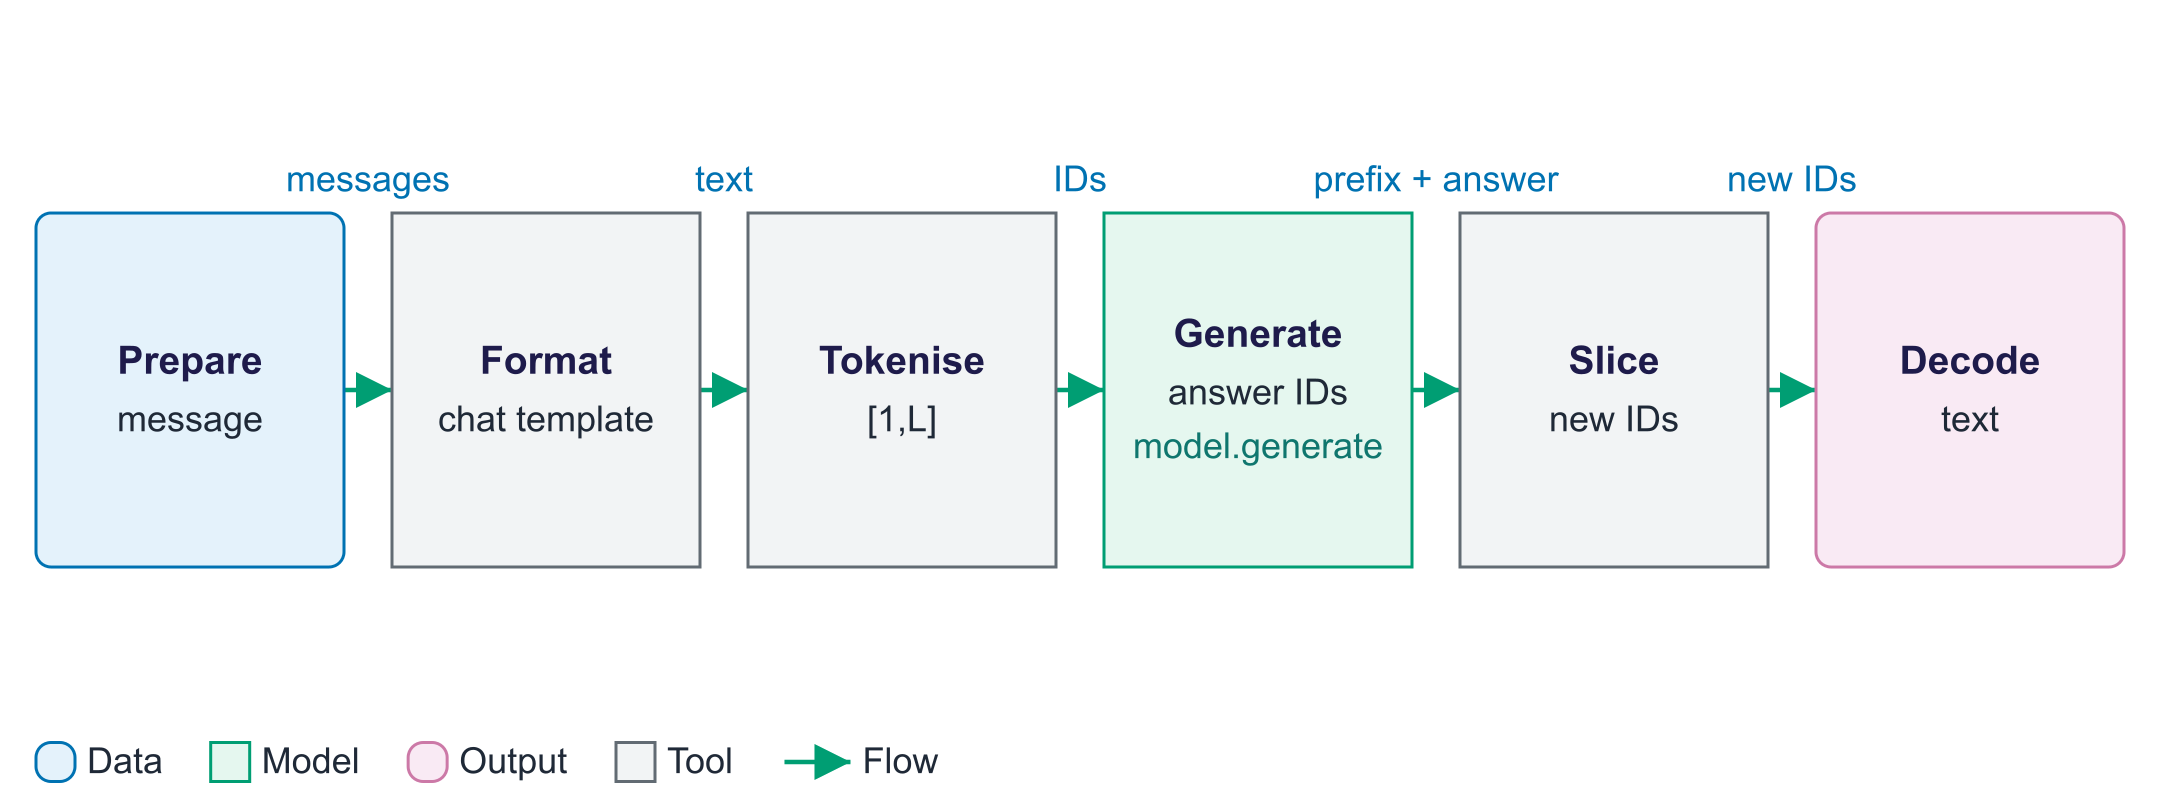
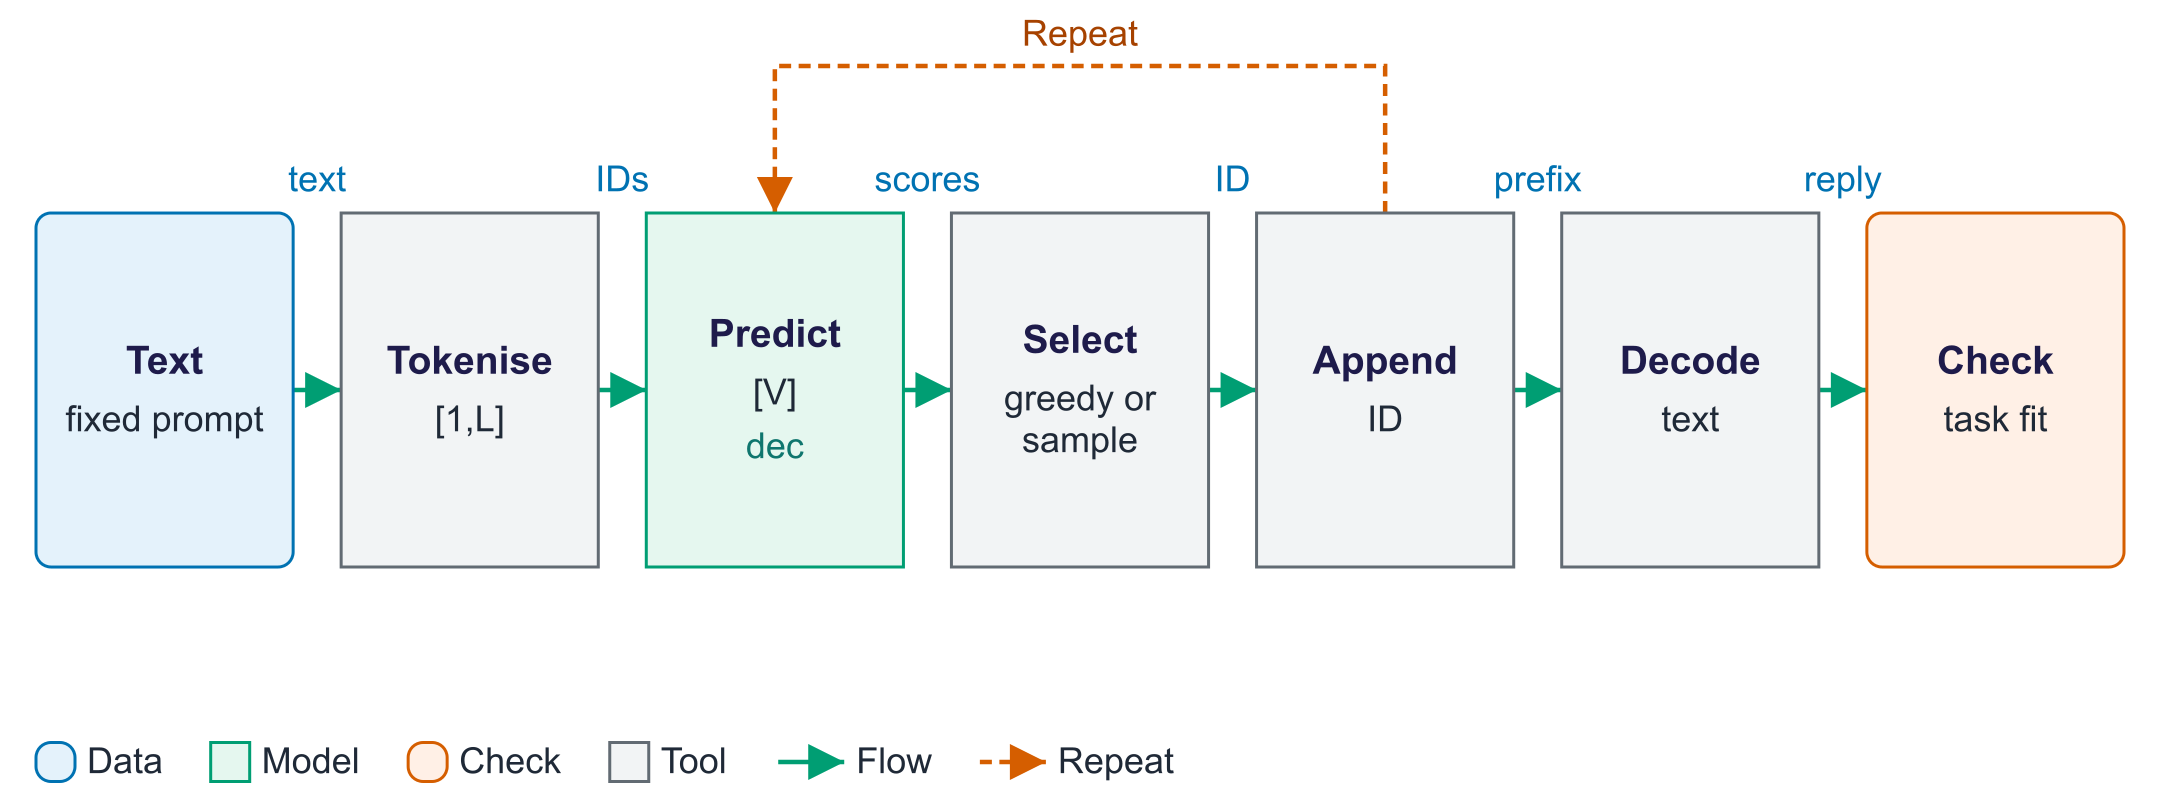

## Read, predict, run, change, check

Predict the output before running each part. Change one setting at a time.
Stop after a TODO until its targeted check succeeds. Model replies may be
wrong: observed output and verified task quality are separate records.

> **How to run this notebook**
> - **Google Colab:** File ▸ Upload notebook. Keep the CPU runtime for the core path. Run cells top to bottom with Shift+Enter. Free resources vary; there is no guaranteed GPU.
> - **Local Jupyter / VS Code:** select a Python 3.11+ kernel with the listed packages. Run the install cell once if needed.
> - **Optional routes:** leave `USE_GPU`, `USE_GEMINI` and `USE_OPENAI` false for the complete local CPU lab. To compare a hosted answer, enable exactly one API switch in shared setup.
> - **Gemini:** use synthetic prompts only. Store `GEMINI_API_KEY` in Colab Secrets or the environment. Account, age, region, quota and distribution terms affect eligibility; see the platform note. Never enable billing for this lab.
> - **OpenAI API:** an optional paid alternative, using `OPENAI_API_KEY` from Secrets or the environment. A ChatGPT subscription does not supply API credit. Check your account's API pricing and budget first. Local users can point `LOCAL_ENV_FILE` to a private `.env`; never upload it or paste keys into notebook cells.
> - Cells marked **TODO** are yours to complete before running dependent cells. Questions marked ✍️ need a short written answer.
> - Read each diagram by following its numbered blocks. The solid arrows carry data to the next block. A dashed arrow shows a step that repeats.

## This week's place in the course

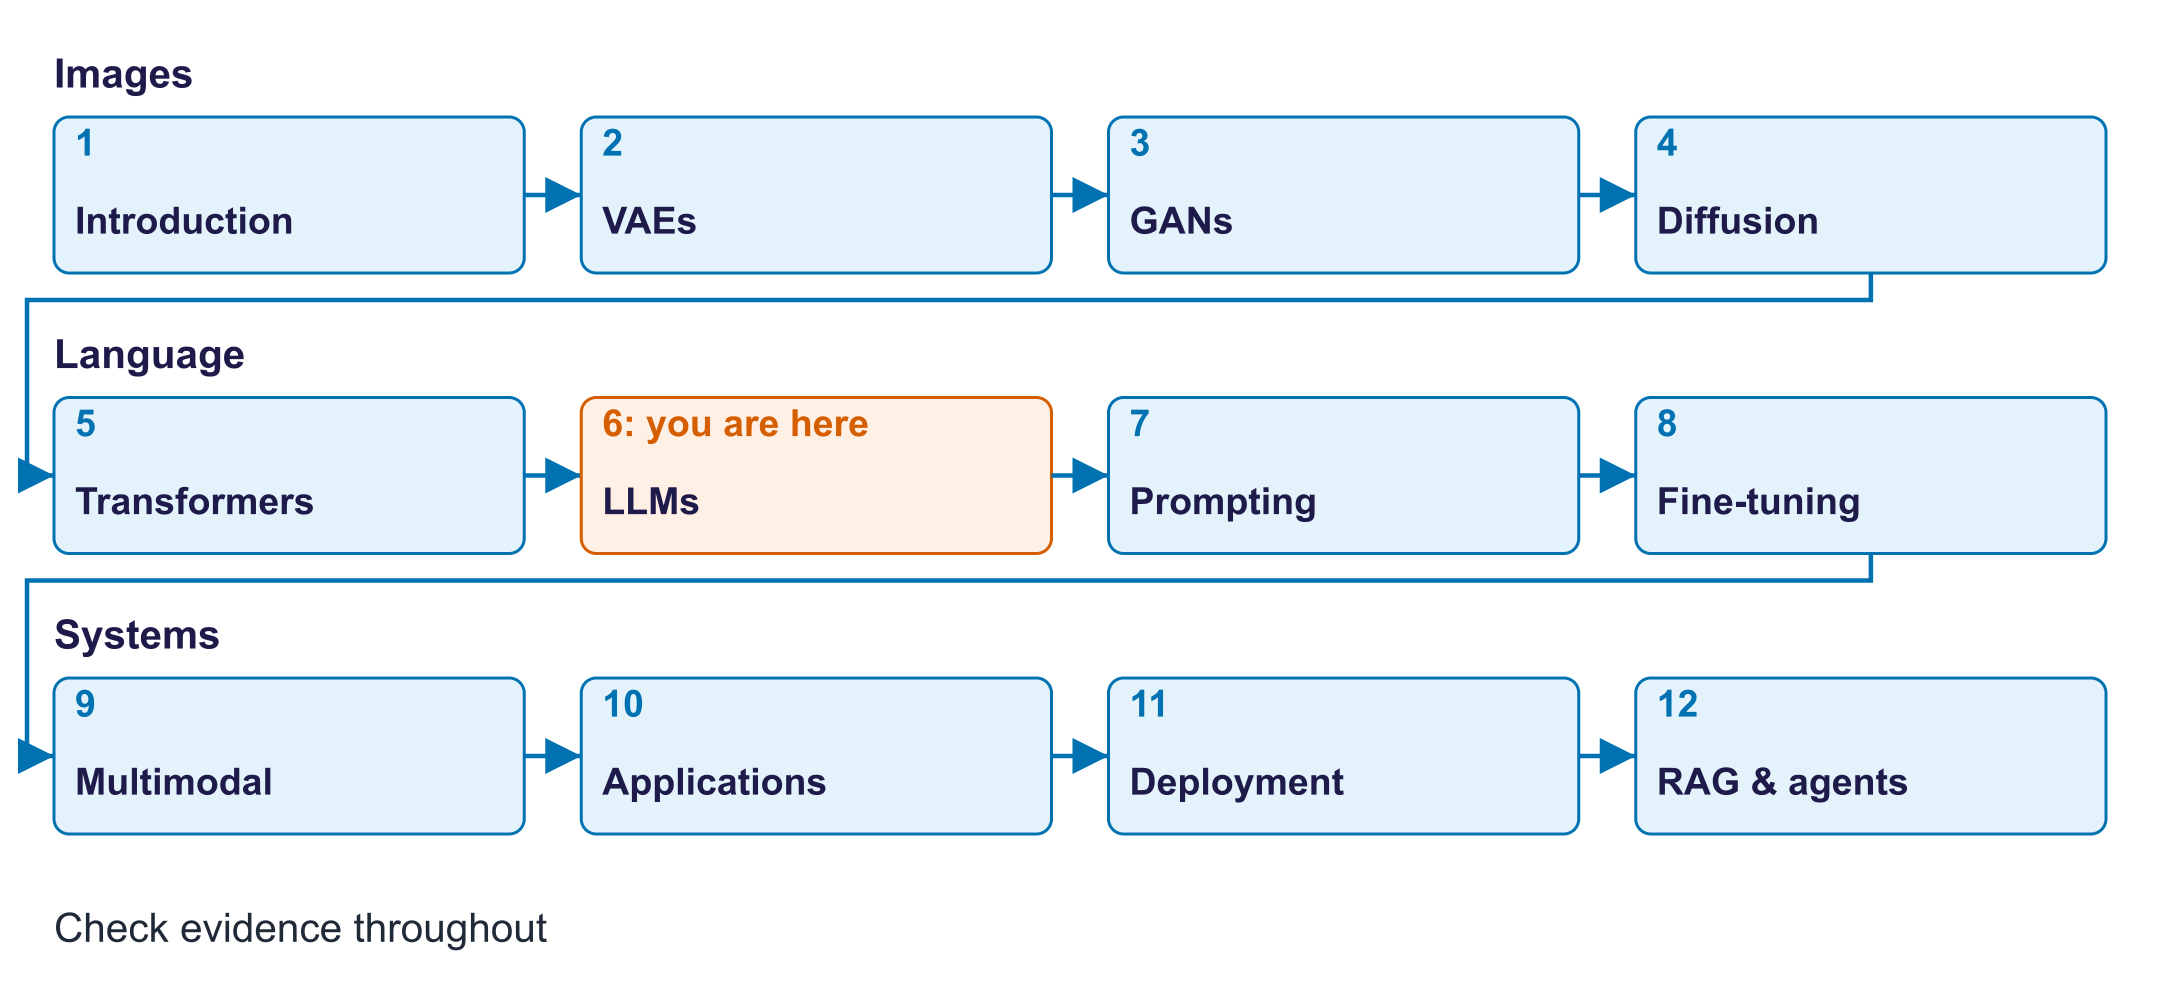

**Purpose:** Install the model and table libraries in Colab.
**Why now:** Later cells import Transformers and display comparison tables.
**Expected output:** Installation messages; local prepared environments skip this cell.

In [ ]:
%pip install -q transformers==5.18.0 accelerate pandas matplotlib ipywidgets==7.7.1
%pip install -q google-genai==2.29.0 ipywidgets==7.7.1 openai==3.28.0 python-dotenv==1.2.4

### Shared setup: choose, reproduce, check

This cell chooses CPU computation, fixes the random seed and prints package versions.
Expect a runtime record and no API request. `check()` prints helpful feedback.

Leave `USE_GEMINI = False` and `USE_OPENAI = False` for the complete local lab.
For an optional comparison, enable exactly one switch and rerun this setup cell.
`ask_model()` selects Gemini (`gemini-3.5-flash-lite`) or the OpenAI API (`gpt-4.1-mini`).
Both use a bounded retry, a shared 40-attempt ceiling and a local response cache.
Free quotas are account-specific; a failed request returns `None` for the local fallback.
Use only invented examples. Students in the EEA, UK and Switzerland should check
the [Gemini terms](https://ai.google.dev/gemini-api/terms) before opting in:
API-client distribution has a separate paid-service condition. Local tasks need no key or billing.
OpenAI API usage may incur charges, separately from ChatGPT subscriptions; check
[API pricing](https://developers.openai.com/api/docs/pricing) before opting in.
Use `GEMINI_API_KEY` or `OPENAI_API_KEY` in Colab Secrets or your local environment.
For local `.env` use, set `LOCAL_ENV_FILE` to that file's path. Secrets are read only after opt-in.
Use invented prompts only. OpenAI requests set `store=False`; this is not a promise of zero retention.

**Common errors:** a missing optional key means use the local result; a package import
error means check the selected kernel and install cell. Change only one switch at a time.

In [ ]:
"""Shared notebook setup, injected by the builder after package installation."""
import importlib.metadata
import importlib.util
import hashlib
import json
import os
from pathlib import Path
import platform
import random
import time

import numpy as np
import torch

# Change a switch only when you choose an optional route. Enable one API at most.
USE_GPU = False
USE_GEMINI = False
USE_OPENAI = False
GEMINI_MODEL = "gemini-3.5-flash-lite"
OPENAI_MODEL = "gpt-4.1-mini"
# Local users may change this path to their private .env file; never upload that file.
LOCAL_ENV_FILE = ".env"
SEED = 42
SMOKE = os.environ.get("GENAI_LAB_SMOKE") == "1"
try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False
# The instructor runner's explicit --device cuda option is also an opt-in.
_gpu_opt_in = USE_GPU or os.environ.get("GENAI_RUNNER_GPU") == "1"
DEVICE = "cuda" if _gpu_opt_in and torch.cuda.is_available() and os.environ.get("GENAI_FORCE_CPU") != "1" else "cpu"
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
# Small CPU jobs often run faster without oversubscribing the machine.
torch.set_num_threads(min(4, os.cpu_count() or 1))
if DEVICE == "cuda":
    torch.cuda.manual_seed_all(SEED)

def check(condition, ok_message, hint):
    """Give feedback without hiding what needs to be corrected."""
    print("✅ " + ok_message if bool(condition) else "Try again: " + hint)
    return bool(condition)

def _package_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return "not installed"

RUNTIME_INFO = {
    "environment": "Colab" if IN_COLAB else "local",
    "python": platform.python_version(), "device": DEVICE, "seed": SEED,
    "platform": platform.platform(), "processor": platform.processor(), "logical_cpus": os.cpu_count(),
    "cpu_threads": torch.get_num_threads(),
    "packages": {name: _package_version(name) for name in (
        "torch", "transformers", "diffusers", "peft", "trl",
        "sentence-transformers", "google-genai", "openai", "python-dotenv", "ipywidgets")},
}
print("Runtime:", json.dumps(RUNTIME_INFO, sort_keys=True))
print("CPU is the default. Complete the core tasks before trying optional GPU or API work.")

_gemini_calls = 0
_openai_calls = 0
_gemini_cache = Path.cwd() / ".genai_cache"

def _optional_key(name):
    """Read a secret only after the student opts in; never display it."""
    if IN_COLAB:
        try:
            from google.colab import userdata
            key = userdata.get(name)
            if key:
                return key
        except Exception:
            pass
    key = os.environ.get(name)
    if key or IN_COLAB:
        return key
    # Read this one file only after explicit API opt-in. Do not change the environment.
    try:
        from dotenv import dotenv_values
        return dotenv_values(LOCAL_ENV_FILE).get(name)
    except Exception:
        return None

def _gemini_key():
    return _optional_key("GEMINI_API_KEY")

def ask_gemini(prompt, *, temperature=0.2, max_output_tokens=256):
    """Return optional synthetic-data text, or None to use the local model.

    Requests, including retries, are capped at 40 per notebook session.
    Actual free quotas and eligibility depend on the student's account.
    """
    global _gemini_calls
    if not USE_GEMINI or SMOKE:
        return None
    key = _gemini_key()
    if not key:
        print("Gemini key unavailable; continue with the local result.")
        return None
    request = {"model": GEMINI_MODEL, "prompt": prompt,
               "temperature": temperature, "max_output_tokens": max_output_tokens}
    digest = hashlib.sha256(json.dumps(request, sort_keys=True).encode("utf-8")).hexdigest()
    cache_file = _gemini_cache / (digest + ".json")
    try:
        if cache_file.exists():
            return json.loads(cache_file.read_text(encoding="utf-8"))["text"]
    except (OSError, ValueError, KeyError):
        pass
    try:
        from google import genai
        from google.genai import types
        client = genai.Client(api_key=key, http_options=types.HttpOptions(
            timeout=30000, retry_options=types.HttpRetryOptions(attempts=1)))
        for attempt in range(4):
            if _gemini_calls + _openai_calls >= 40:
                print("Notebook request ceiling reached; use the local result.")
                return None
            _gemini_calls += 1
            try:
                response = client.models.generate_content(
                    model=GEMINI_MODEL, contents=prompt,
                    config=types.GenerateContentConfig(
                        temperature=temperature, max_output_tokens=max_output_tokens),
                )
                text = response.text
                if not isinstance(text, str) or not text.strip():
                    return None
                try:
                    _gemini_cache.mkdir(exist_ok=True)
                    cache_file.write_text(json.dumps({"text": text}), encoding="utf-8")
                except OSError:
                    pass
                return text
            except Exception as error:
                # Error messages can contain request details, so display no raw exception.
                if getattr(error, "code", None) != 429 or attempt == 3:
                    print("Gemini unavailable; continue with the local result.")
                    return None
                time.sleep(2 ** attempt)
    except Exception:
        print("Gemini setup unavailable; continue with the local result.")
    finally:
        if "client" in locals() and hasattr(client, "close"):
            try:
                client.close()
            except Exception:
                pass
    return None

def ask_openai(prompt, *, temperature=0.2, max_output_tokens=256):
    """Return optional OpenAI API text, or None for the complete local fallback.

    API usage may incur charges and is separate from a ChatGPT subscription.
    The notebook ceiling counts both providers' attempts, including retries.
    """
    global _openai_calls
    if not USE_OPENAI or SMOKE:
        return None
    key = _optional_key("OPENAI_API_KEY")
    if not key:
        print("OpenAI key unavailable; continue with the local result.")
        return None
    request = {"provider": "openai", "model": OPENAI_MODEL, "prompt": prompt,
               "temperature": temperature, "max_output_tokens": max_output_tokens}
    digest = hashlib.sha256(json.dumps(request, sort_keys=True).encode("utf-8")).hexdigest()
    cache_file = _gemini_cache / (digest + ".json")
    try:
        if cache_file.exists():
            return json.loads(cache_file.read_text(encoding="utf-8"))["text"]
    except (OSError, ValueError, KeyError):
        pass
    try:
        from openai import OpenAI
        # The helper owns retries so each network attempt counts towards the ceiling.
        client = OpenAI(api_key=key, timeout=30.0, max_retries=0)
        for attempt in range(4):
            if _gemini_calls + _openai_calls >= 40:
                print("Notebook request ceiling reached; use the local result.")
                return None
            _openai_calls += 1
            try:
                response = client.responses.create(
                    model=OPENAI_MODEL, input=prompt, temperature=temperature,
                    max_output_tokens=max_output_tokens, store=False,
                )
                text = response.output_text
                if not isinstance(text, str) or not text.strip():
                    return None
                try:
                    _gemini_cache.mkdir(exist_ok=True)
                    cache_file.write_text(json.dumps({"text": text}), encoding="utf-8")
                except OSError:
                    pass
                return text
            except Exception as error:
                if getattr(error, "status_code", None) != 429 or attempt == 3:
                    print("OpenAI unavailable; continue with the local result.")
                    return None
                time.sleep(2 ** attempt)
    except Exception:
        print("OpenAI setup unavailable; continue with the local result.")
    finally:
        if "client" in locals() and hasattr(client, "close"):
            try:
                client.close()
            except Exception:
                pass
    return None

def ask_model(prompt, *, temperature=0.2, max_output_tokens=256):
    """Use the student's one selected API, otherwise return None for local work."""
    if SMOKE:
        return None
    if USE_GEMINI and USE_OPENAI:
        print("Choose one API switch; keep the other False. Use the local result for now.")
        return None
    if USE_GEMINI:
        return ask_gemini(prompt, temperature=temperature, max_output_tokens=max_output_tokens)
    if USE_OPENAI:
        return ask_openai(prompt, temperature=temperature, max_output_tokens=max_output_tokens)
    return None


**Purpose:** Import tools and choose bounded core settings.
**Why now:** Shared setup already supplies the device, seeds and provider controls.
**Expected output:** Three readiness checks, a CPU device and disabled stretch flags.

In [ ]:
import math
import os
import random
import re
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from transformers import AutoModelForCausalLM, AutoModelForSeq2SeqLM, AutoTokenizer, pipeline

pd.set_option("display.max_colwidth", 120)
DECODER_ID = "HuggingFaceTB/SmolLM2-135M-Instruct"
QWEN_ID = "Qwen/Qwen2.5-0.5B-Instruct"
CPU_QUICK = DEVICE == "cpu" and os.environ.get("GENAI_FULL_CPU") != "1"
T5_ID = "google/flan-t5-small" if (SMOKE or CPU_QUICK) else "google/flan-t5-base"
CORE_NEW_TOKENS = 8 if SMOKE else 24
MANUAL_STEPS = 4 if SMOKE else 16
RUN_TOKENIZER_STRETCH = False
RUN_FAMILY_STRETCH = False
RUN_REASONING_STRETCH = False

ready = check(abs(sum([0.6, 0.3, 0.1]) - 1) < 1e-8,
              "The three probabilities sum to one.", "Add every candidate probability before calling it a distribution.")
ready &= check(torch.tensor([[1, 2, 3]]).shape == (1, 3),
               "[1, 3] means one sequence of three token IDs.", "The first dimension counts sequences, not vocabulary entries.")
ready &= check([1, 2, 3, 4][3:] == [4],
               "Slicing at the prefix length leaves only new IDs.", "A decoder returns the prefix followed by its continuation.")
assert ready, "Review these array/probability examples before continuing."
print("Core device:", DEVICE, "| checkpoint:", DECODER_ID, "| generation cap:", CORE_NEW_TOKENS)

## Part 1 · Token pieces and whitespace words

> **Core:** compare the core tokenizer with BERT's tokenizer on the same texts.
> **Change one thing:** add an accented name and inspect its pieces.
> **Optional stretch:** enable `RUN_TOKENIZER_STRETCH` to add GPT-2, T5 and Qwen tokenizers.
> **Common errors:** token pieces need not coincide with whitespace words.

**Predict:** can two tokenizers assign different IDs to the same word?
**TODO 1:** calculate token count and tokens per whitespace-delimited word.
**Hint:** count `input_ids` with `add_special_tokens=False`, then divide by
`len(text.split())`. The examples are nonempty. Five pieces for two words
gives 2.5; that arithmetic is an illustration, not a measured tokenizer result.

**Purpose:** Implement token counting and inspect real tokenizer outputs.
**Why now:** Token budgets and per-token measurements depend on these pieces.
**Expected output:** A passed counting check, a comparison table and token pieces.

In [ ]:
def token_statistics(tok, text):
    n_tokens, per_word = 0, 0.0  # TODO 1
    return n_tokens, per_word

def check_token_statistics(fn):
    class SyntheticTokenizer:
        def __call__(self, text, add_special_tokens=True):
            self.special = add_special_tokens
            return {"input_ids": [10, 11] if text == "one" else [10, 11, 12, 13, 14]}
    try:
        probe = SyntheticTokenizer()
        one, two = fn(probe, "one"), fn(probe, "two words")
        ok = one == (2, 2.0) and two == (5, 2.5) and probe.special is False
    except (TypeError, ValueError, KeyError, ZeroDivisionError, AttributeError):
        ok = False
    return check(ok, "TODO 1 counts pieces and divides by whitespace words.",
                 "Read input_ids, exclude special markers and count words in the original text.")

assert check_token_statistics(token_statistics), "Complete TODO 1 before comparing tokenizers."
texts = {
    "English": "Large language models predict the next token. Tokenisers split text into pieces.",
    "Irish": "Tuarann samhlacha móra teanga an chéad chomhartha eile. Roinneann tokenizers téacs ina phíosaí.",
    "Code": "def softmax(z):\n    e = np.exp(z - z.max())\n    return e / e.sum()",
}
tokenizers = {"SmolLM2": DECODER_ID, "BERT": "bert-base-uncased"}
if RUN_TOKENIZER_STRETCH and not SMOKE:
    tokenizers.update({"GPT-2": "gpt2", "Flan-T5": T5_ID, "Qwen2.5": QWEN_ID})
rows, loaded_tokenizers = [], {}
for name, mid in tokenizers.items():
    tok = AutoTokenizer.from_pretrained(mid)
    loaded_tokenizers[name] = tok
    for tname, text in texts.items():
        n_tokens, per_word = token_statistics(tok, text)
        rows.append({"tokenizer": name, "vocab": len(tok), "text": tname,
                     "tokens": n_tokens, "tokens/word": round(per_word, 2)})
df_tok = pd.DataFrame(rows).pivot(index="tokenizer", columns="text", values="tokens/word")
print(df_tok)
tok = loaded_tokenizers["SmolLM2"]
for word in ["unbelievable", "Dublin", "Dún Laoghaire", "ChatGPT", "   indentation"]:
    print(repr(word), "→", tok.tokenize(word))

## Part 2 · Match the architecture to the job

> **Core:** run the small decoder and inspect the Word notes' recorded BERT/T5/Qwen examples.
> **Change one thing:** change an instruction while keeping the checkpoint and token cap fixed.
> **Optional stretch:** enable `RUN_FAMILY_STRETCH` for live BERT, Flan-T5 and Qwen comparisons.
> **Common errors:** filling one mask and generating an entire answer are different tasks.

BERT ranks a missing token in supplied context. T5 encodes a source and
generates separate text. The decoder appends successive answer tokens.
The stored family table uses different checkpoints from this new CPU core.
Record those checkpoint names before comparing its observed successes or errors.

**Purpose:** Load one small decoder and format its chat request correctly.
**Why now:** One checkpoint makes later decoding and predictability comparisons controlled.
**Expected output:** Parameter dtype, input shape, short answers and generated-token counts.

In [ ]:
dec_tok = loaded_tokenizers["SmolLM2"]
# Keep full precision explicit; optional GPU use does not require fp16.
dec = AutoModelForCausalLM.from_pretrained(DECODER_ID, dtype=torch.float32).to(DEVICE).eval()

def chat(model, tok, question, max_new_tokens=80, sampling=None, **template_kw):
    """Use greedy decoding unless sampling supplies explicit generation settings."""
    msgs = [{"role": "user", "content": question}]
    inputs = tok.apply_chat_template(msgs, add_generation_prompt=True,
                                    return_tensors="pt", return_dict=True, **template_kw).to(DEVICE)
    budget = (16 if SMOKE else max_new_tokens if template_kw.get("enable_thinking")
              else min(max_new_tokens, 40) if CPU_QUICK else max_new_tokens)
    if template_kw.get("enable_thinking") and not (sampling or {}).get("do_sample", False):
        raise ValueError("Qwen3 thinking mode requires its recommended sampled settings, not greedy decoding.")
    t0 = time.perf_counter()
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=budget, pad_token_id=tok.eos_token_id,
                             **(sampling or {"do_sample": False}))
    new = out[0, inputs["input_ids"].shape[1]:]
    return tok.decode(new, skip_special_tokens=True).strip(), len(new), time.perf_counter() - t0

TASKS = {
    "QA": "What is the capital of Ireland?",
    "Translate": "Translate English to German: How old are you?",
    "Summarise": "Summarize in one sentence: Generative models learn distributions and sample new examples. VAEs, GANs, diffusion models and language models use different mechanisms.",
    "Sentiment": "Is this fictional review positive or negative? 'The lab was confusing and the code kept crashing.'",
}
print("Parameter dtype:", next(dec.parameters()).dtype)
example = dec_tok.apply_chat_template([{"role":"user", "content":TASKS["QA"]}],
                                     add_generation_prompt=True, return_tensors="pt", return_dict=True)
example_ids = example["input_ids"]  # the template returns IDs and an attention mask
print("Chat input shape:", tuple(example_ids.shape))
results = []
for name, question in TASKS.items():
    ans, n, sec = chat(dec, dec_tok, question, max_new_tokens=CORE_NEW_TOKENS)
    results.append({"task": name, "checkpoint": DECODER_ID, "answer": ans,
                    "new_tokens": n, "seconds": round(sec, 3)})
print(pd.DataFrame(results))

**Purpose:** Keep the original three-family experiment as an opt-in stretch.
**Why now:** It exposes genuine differences between mask filling, text-to-text and chat.
**Expected output:** A skipped message by default; model outputs only after explicit opt-in.
Additional model downloads and waiting are outside the required CPU core.

In [ ]:
t5_tok, t5, fill = None, None, None

def t5_generate(prompt, max_new_tokens=40):
    ids = t5_tok(prompt, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        out = t5.generate(**ids, max_new_tokens=max_new_tokens)
    return t5_tok.decode(out[0], skip_special_tokens=True)

if RUN_FAMILY_STRETCH and not SMOKE:
    fill = pipeline("fill-mask", model="bert-base-uncased", device=0 if DEVICE == "cuda" else -1)
    for sentence in ["The capital of Ireland is [MASK].", "Generative models can [MASK] new images.",
                     "The doctor said [MASK] would call back later."]:
        print(sentence, "→", [(r["token_str"], round(r["score"], 2)) for r in fill(sentence)[:4]])
    t5_tok = AutoTokenizer.from_pretrained(T5_ID)
    t5 = AutoModelForSeq2SeqLM.from_pretrained(T5_ID, dtype=torch.float32).to(DEVICE).eval()
    qwen_tok = AutoTokenizer.from_pretrained(QWEN_ID)
    qwen = AutoModelForCausalLM.from_pretrained(QWEN_ID, dtype=torch.float32).to(DEVICE).eval()
    family_rows = []
    for name, question in TASKS.items():
        ans, n, sec = chat(qwen, qwen_tok, question, max_new_tokens=40)
        family_rows.append({"task":name, "Flan-T5":t5_generate(question), "Qwen2.5":ans})
    print(pd.DataFrame(family_rows))
else:
    print("Family-model downloads skipped. Inspect the separately recorded family table in the Word notes.")

✍️ **Question 1.** Which jobs suit BERT, T5 and a decoder? Report any actual errors in the core reply or the recorded family examples.
*✍️ Write your answer here.*

## Part 3 · Scores, filters and sampling

> **Core:** implement two filters and compare short greedy, beam and sampled continuations.
> **Change one thing:** use the probability slider to change temperature while keeping scores fixed.
> **Optional stretch:** increase the continuation length and measure the additional waiting.
> **Common errors:** temperature must be positive in softmax; greedy uses `do_sample=False`.

**TODO 2:** retain scores at or above the kth-largest score; exclude the rest with −∞.
**Hint:** `torch.topk(...).values[..., -1, None]` gives the broadcast threshold.
Ties can retain more than k candidates: preserve this original threshold contract.
**TODO 3:** retain the smallest descending-probability prefix reaching p.
**Hint:** remove candidates whose preceding cumulative probability is already ≥p,
then scatter scores back to their original positions. Always keep the highest candidate.
A logit is an unnormalised score. Removed scores become zero probability after softmax.

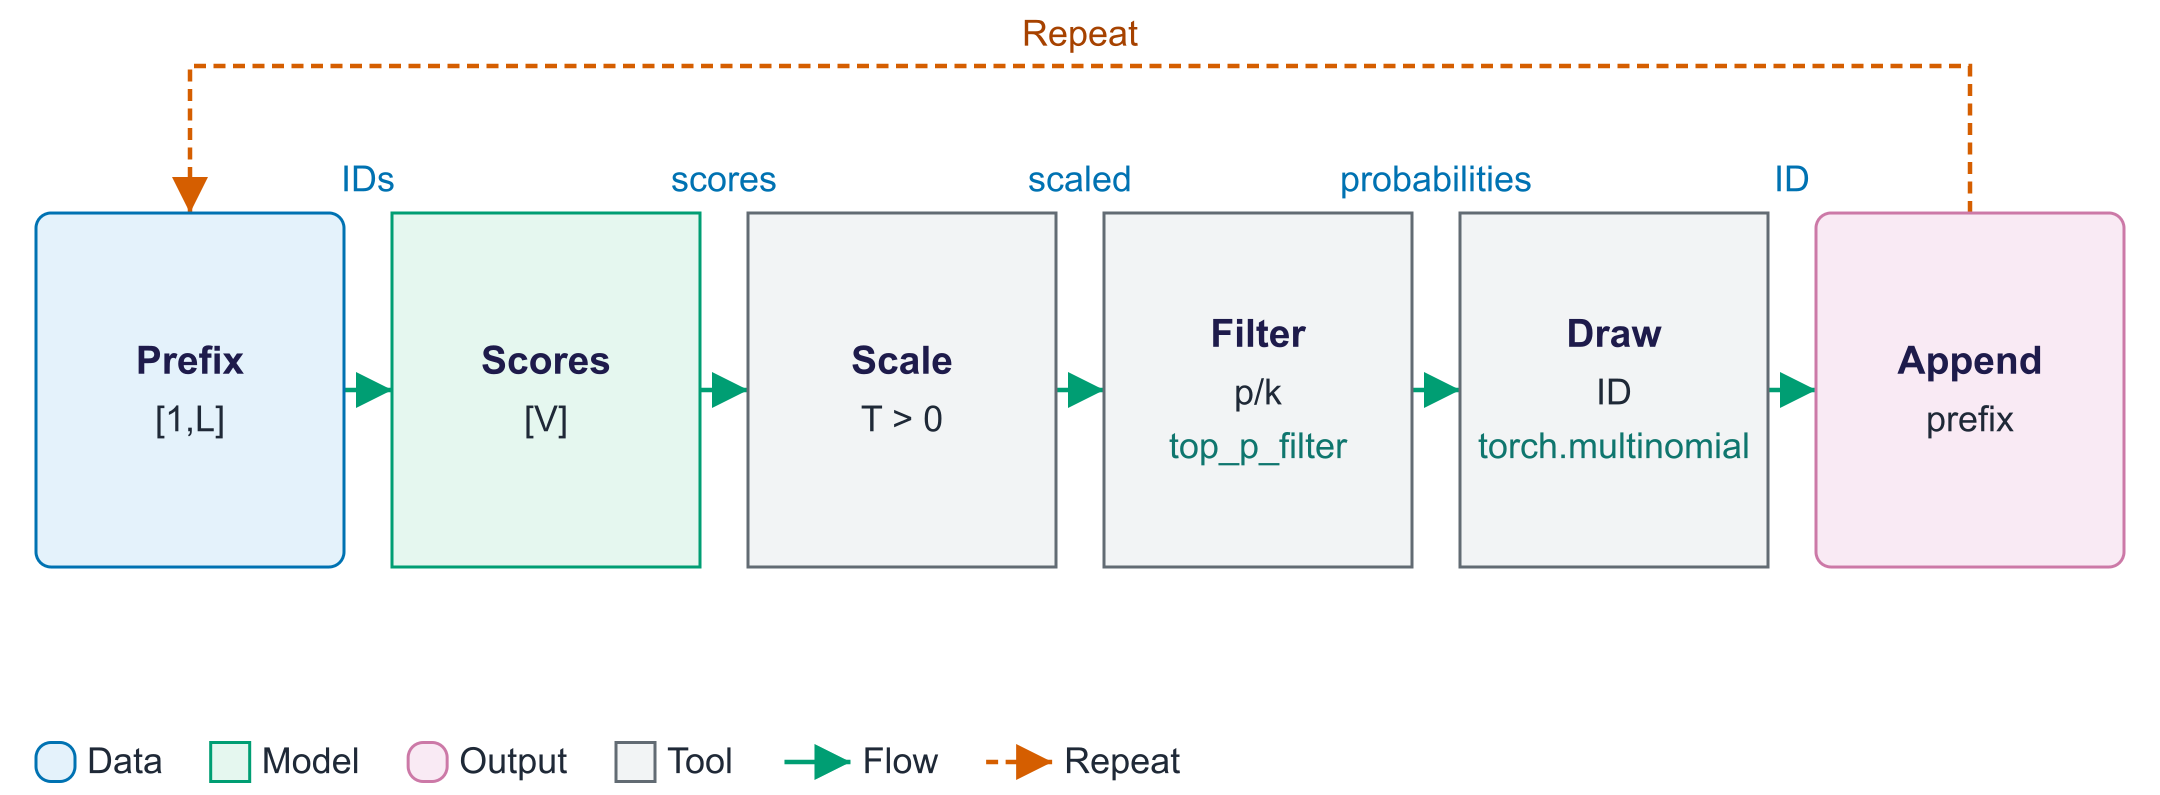
For scores [2, 1, 0.5, 0.1, −1], p=0.8 retains three candidates. This is a worked example.
**Predict:** why can the retained count change at the next position?
*✍️ Write your answer here.*

**Purpose:** Implement and check top-k and top-p on known scores.
**Why now:** A short independent check isolates filtering errors before expensive generation.
**Expected output:** Two passed targeted checks and the retained probabilities.

In [ ]:
def top_k_filter(logits, k):
    pass  # TODO: write your code here

def top_p_filter(logits, p):
    pass  # TODO: write your code here

def check_top_k_filter(fn):
    try:
        scores = torch.tensor([[2., 1., .5, .1, -1.], [1., 2., 2., 0., -1.]])
        got = fn(scores, 2)
        kept = torch.isfinite(got)
        expected = torch.tensor([[True, True, False, False, False], [False, True, True, False, False]])
        tied = fn(torch.tensor([2., 1., 1., 0.]), 2)
        ok = got.shape == scores.shape and torch.equal(kept, expected)
        ok = bool(ok and torch.equal(got[kept], scores[kept]) and torch.isfinite(tied).sum() == 3)
    except (TypeError, ValueError, RuntimeError, AttributeError):
        ok = False
    return check(ok, "TODO 2 preserves the top-k threshold, retained scores and ties.",
                 "Compare each score with the kth value; keep tied boundary scores and use negative infinity elsewhere.")

def check_top_p_filter(fn):
    try:
        scores = torch.tensor([.1, 2., -1., 1., .5])
        got = fn(scores, .8)
        expected = torch.tensor([False, True, False, True, True])
        ok = got.shape == scores.shape and torch.equal(torch.isfinite(got), expected)
        ok = bool(ok and torch.equal(got[expected], scores[expected]))
        ok = bool(ok and torch.isfinite(fn(scores, .01)).sum() == 1
                  and torch.isfinite(fn(scores, 1.)).sum() == len(scores))
    except (TypeError, ValueError, RuntimeError, AttributeError):
        ok = False
    return check(ok, "TODO 3 reaches the requested mass and restores original candidate positions.",
                 "Keep the boundary-crossing token; test a tiny p and p=1, then scatter using sorted indices.")

assert check_top_k_filter(top_k_filter), "Complete TODO 2 before generation."
assert check_top_p_filter(top_p_filter), "Complete TODO 3 before generation."
test = torch.tensor([2.0, 1.0, 0.5, 0.1, -1.0])
print("Score shape:", tuple(test.shape), "| probabilities:", test.softmax(-1).numpy().round(3))
print("Retained probabilities:", top_p_filter(test, .8).softmax(-1).numpy().round(3))

**Purpose:** Explore temperature and p using fixed synthetic scores.
**Why now:** Holding scores fixed isolates the token-selection policy from model prediction.
**Expected output:** Five candidate probabilities; this widget calls no model or API.
If widgets are unavailable, call `show_policy(temperature=1.0, p=0.8)` directly.

In [ ]:
def show_policy(temperature=1.0, p=0.8):
    scores = torch.tensor([2.0, 1.0, 0.5, 0.1, -1.0]) / temperature
    probs = top_p_filter(scores, p).softmax(-1).numpy()
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.bar(["A", "B", "C", "D", "E"], probs)
    ax.set_ylim(0, 1); ax.set_ylabel("retained probability")
    ax.set_title(f"T={temperature:.2f}, p={p:.2f}; sum={probs.sum():.3f}")
    plt.show()

try:
    import ipywidgets as widgets
    from IPython.display import display
    display(widgets.interactive(show_policy,
        temperature=widgets.FloatSlider(value=1., min=.2, max=2., step=.1, continuous_update=False),
        p=widgets.FloatSlider(value=.8, min=.1, max=1., step=.05, continuous_update=False)))
except ImportError:
    show_policy()
    print("Change the arguments of show_policy to explore without widgets.")

**Purpose:** Generate short continuations with the same real model and prefix.
**Why now:** Changing selection rules can change text while weights stay fixed.
**Expected output:** Five short outputs and distinct-2 values, with settings recorded.
Distinct-2 counts unique whitespace word pairs and includes the shared prefix.
It measures repetition; it does not measure correctness or overall writing quality.

In [ ]:
@torch.no_grad()
def sample(prompt, n_new=40, temperature=1.0, k=None, p=None, seed=0):
    if temperature <= 0:
        raise ValueError("Sampling temperature must be positive; use do_sample=False for greedy generation.")
    torch.manual_seed(seed)
    ids = dec_tok(prompt, return_tensors="pt")["input_ids"].to(DEVICE)
    # Preserve the original fixed-step teaching loop; it has no explicit EOS stop.
    for _ in range(4 if SMOKE else n_new):
        # Float32 avoids reduced-precision softmax/mass comparisons.
        logits = dec(ids).logits[0, -1].float() / temperature
        if k:
            logits = top_k_filter(logits, k)
        if p:
            logits = top_p_filter(logits, p)
        nxt = torch.multinomial(logits.softmax(-1), 1)
        ids = torch.cat([ids, nxt[None]], dim=1)
    return dec_tok.decode(ids[0], skip_special_tokens=True)

prompt = "Once upon a time in a small village by the sea,"
ids = dec_tok(prompt, return_tensors="pt").to(DEVICE)
with torch.no_grad():
    greedy = dec_tok.decode(dec.generate(**ids, max_new_tokens=MANUAL_STEPS, do_sample=False,
                                        pad_token_id=dec_tok.eos_token_id)[0], skip_special_tokens=True)
    beam = dec_tok.decode(dec.generate(**ids, max_new_tokens=MANUAL_STEPS, num_beams=4, do_sample=False,
                                      pad_token_id=dec_tok.eos_token_id)[0], skip_special_tokens=True)
outputs = {"greedy":greedy, "beam (4)":beam,
           "T=1.0, top-k 50":sample(prompt, n_new=MANUAL_STEPS, k=50),
           "T=0.7, top-p 0.9":sample(prompt, n_new=MANUAL_STEPS, temperature=.7, p=.9),
           "T=1.5 (no filter)":sample(prompt, n_new=MANUAL_STEPS, temperature=1.5)}
for rule, text in outputs.items():
    print(rule, "→", text)

def distinct_2(text):
    toks = text.split()
    bigrams = list(zip(toks, toks[1:]))
    return len(set(bigrams)) / max(1, len(bigrams))

print({rule:round(distinct_2(text), 2) for rule, text in outputs.items()})

✍️ **Question 2.** Which selection rule would you test for a story, a date extraction and a translation? Does higher distinct-2 establish accuracy?
*✍️ Write your answer here.*

## Part 4 · Perplexity within one model/tokenizer pair

> **Core:** score four short supplied texts with the existing core model.
> **Change one thing:** shuffle the same words using the saved local seed.
> **Optional stretch:** compare GPT-2 with its own tokenizer, reporting each pair separately.
> **Common errors:** lower cross-tokenizer perplexity does not establish better answers.

**TODO 4:** convert mean negative log-likelihood (NLL) into perplexity.
**Hint:** calculate `math.exp(loss)`; for loss ln(2), perplexity is 2.
The model internally shifts labels to score next tokens. This is held-out
scoring with gradients disabled; no optimiser changes its weights.

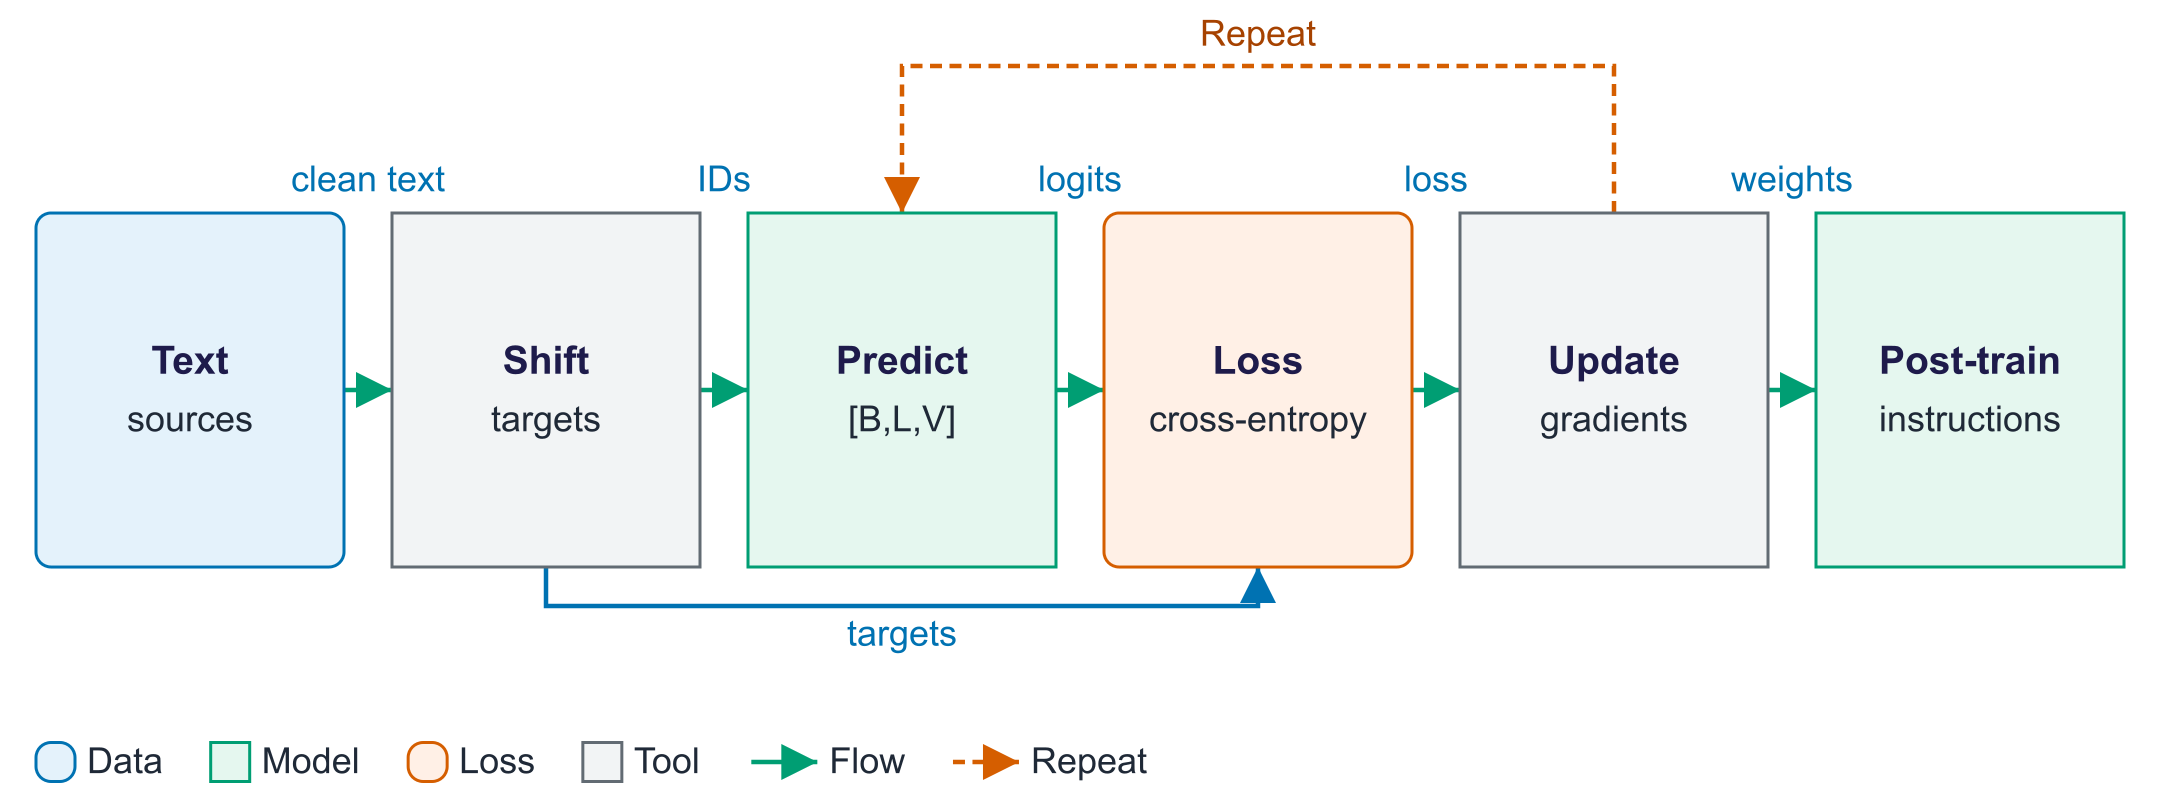
**Predict:** does the upcoming scoring cell perform the training update shown here?
*✍️ Write your answer here.*

**Purpose:** Implement perplexity and measure supplied-text predictability.
**Why now:** The same tokenizer/model pair makes the four inputs comparable in their prediction units.
**Expected output:** A passed exponential check and four measured scores; inspect the ordering yourself.

In [ ]:
@torch.no_grad()
def perplexity(model, tok, text):
    ids = tok(text, return_tensors="pt").to(DEVICE)
    loss = model(**ids, labels=ids["input_ids"]).loss.item()
    pass  # TODO: write your code here

def check_perplexity(fn):
    class Batch(dict):
        def to(self, device):
            return self
    class SyntheticTokenizer:
        def __call__(self, text, return_tensors):
            return Batch(input_ids=torch.tensor([[1, 2, 3]]))
    class KnownLoss:
        def __call__(self, input_ids, labels):
            assert torch.equal(input_ids, labels)
            self.called = True
            return type("Output", (), {"loss":torch.tensor(math.log(2.), dtype=torch.float32)})()
    try:
        probe = KnownLoss()
        got = fn(probe, SyntheticTokenizer(), "synthetic held-out text")
        ok = probe.called and isinstance(got, (float, int)) and abs(got - 2.) < 1e-6
    except (TypeError, ValueError, RuntimeError, AttributeError, AssertionError):
        ok = False
    return check(ok, "TODO 4 converts mean next-token NLL to exp(loss).",
                 "Use the exponential, not the loss itself or 1/loss; keep supplied IDs as labels.")

assert check_perplexity(perplexity), "Complete TODO 4 before interpreting scores."
s = "The students trained a small language model and measured its perplexity on held-out text."
words = s.split()
samples = {"normal":s, "shuffled words":" ".join(random.Random(SEED).sample(words, len(words))),
           "Irish":texts["Irish"], "code":texts["Code"]}
ppl_rows = [{"text":name, "checkpoint":DECODER_ID, "PPL":round(perplexity(dec, dec_tok, text), 3)}
            for name, text in samples.items()]
print(pd.DataFrame(ppl_rows))
if RUN_FAMILY_STRETCH and not SMOKE:
    gpt2_tok = AutoTokenizer.from_pretrained("gpt2")
    gpt2 = AutoModelForCausalLM.from_pretrained("gpt2", dtype=torch.float32).to(DEVICE).eval()
    print(pd.DataFrame([{"text":name, "GPT-2 PPL":round(perplexity(gpt2, gpt2_tok, text), 3)}
                        for name, text in samples.items()]))

✍️ **Question 3.** Describe your four scores. Why can a differently tokenised model's smaller number not prove better question answering?
*✍️ Write your answer here.*

## Part 5 · Local request log and optional provider feedback

> **Core:** time one local invented-example request and verify its content.
> **Change one thing:** request one sentence instead of two, keeping the checkpoint fixed.
> **Optional stretch:** enable exactly one shared Gemini/OpenAI switch for the same fictional prompt.
> **Common errors:** API text is not local token IDs; an unknown usage count must remain missing.

The shared `ask_model` returns text or None. It handles keys, clients,
bounded retries and provider controls. Do not add another SDK or key reader.
Local timing includes formatting/generation in `chat`; the hosted row below
times the wrapper call, including its retries. These boundaries differ.

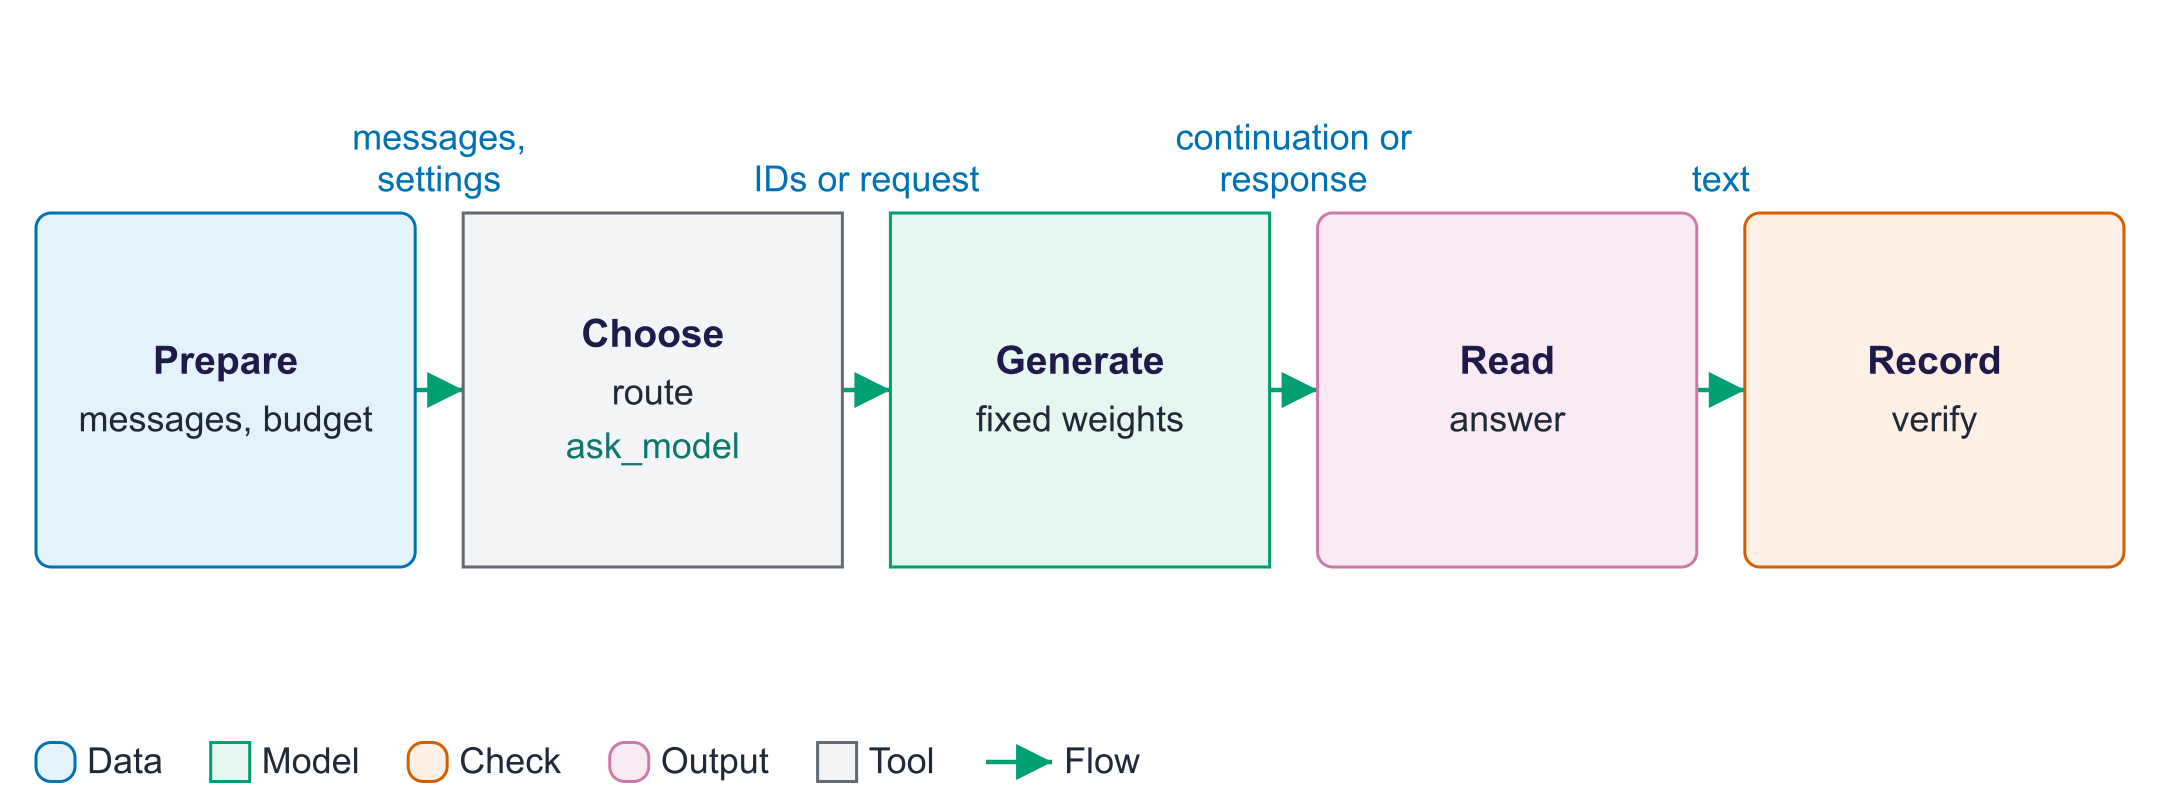
**Predict:** why can two providers have different token counts for identical wording?
*✍️ Write your answer here.*

**Purpose:** Keep a local response and rubric even when no hosted call is available.
**Why now:** An optional service must not block the complete CPU learning route.
**Expected output:** A local log row, a verification rubric and optionally a hosted-text row.

In [ ]:
question = "For a fictional study guide, explain the difference between an encoder-only and a decoder-only transformer in two sentences."
ans, n, sec = chat(dec, dec_tok, question, max_new_tokens=CORE_NEW_TOKENS)
log = [{"route":"local Transformers", "model":DECODER_ID, "seconds":round(sec, 3),
        "prompt_tokens":None, "completion_tokens":n, "answer":ans}]
local_rubric = "An encoder represents supplied input; a decoder predicts successive output tokens. Verify both roles, not just fluency."
t0 = time.perf_counter()
hosted = ask_model(question, temperature=.2, max_output_tokens=128)
if hosted is not None:
    log.append({"route":"selected shared provider", "model":"see shared setup", "seconds":round(time.perf_counter() - t0, 3),
                "prompt_tokens":None, "completion_tokens":None, "answer":hosted})
print("Local rubric:", local_rubric)
print(pd.DataFrame(log))
if hosted is None:
    print("No provider response. The local row and rubric complete this part.")

## Part 6 · Check reasoning answers before spending extra tokens

> **Core:** solve two problems and check the final-answer/completion scorer on synthetic responses.
> **Change one thing:** remove a closing thinking marker or exhaust the cap; predict the score.
> **Optional stretch:** enable `RUN_REASONING_STRETCH` for the original Qwen3 sampled experiment.
> **Common errors:** do not score an unfinished thinking trace as a completed final answer.

The word problem's answer is 21. For the scheduling puzzle, only one run
using two GPUs fits on three GPUs at once: five runs × four hours = 20 hours.

The companion notes show a separately measured Qwen3-0.6B experiment. Its
thinking/non-thinking settings also differ in sampling and budgets. This
compares complete configurations, not an isolated effect of the thinking switch.
Qwen3's official card recommends sampled thinking (T=.6, top-p=.95, top-k=20).
Greedy thinking can repeat; a short capped trace is not proof of reasoning quality.

**Purpose:** Test final-answer extraction and preserve the optional reasoning experiment.
**Why now:** Completion, correctness, token usage and time must be considered together.
**Expected output:** Passed synthetic scoring checks; live Qwen3 rows only after explicit opt-in.

In [ ]:
R_ID = "Qwen/Qwen3-0.6B"
SAMPLING = {True:dict(do_sample=True, temperature=.6, top_p=.95, top_k=20),
            False:dict(do_sample=True, temperature=.7, top_p=.8, top_k=20)}
BUDGET = {True:256, False:80} if CPU_QUICK else {True:2048, False:300}
PROBLEMS = {
    "word problem":("Tom has 3 boxes with 4 apples each. He gives away 5 apples, then buys twice as many apples as he has left. How many apples does he have now? Answer with a number.", 21),
    "scheduling puzzle":("A lab has 3 GPUs. Each training run needs 2 GPUs for 4 hours. How many hours are needed to finish 5 runs if runs can execute in parallel whenever GPUs are free? Answer with a number.", 20),
}

def score_reasoning_answer(ans, n, budget, think, gold):
    final = ans.split("</think>")[-1]
    nums = re.findall(r"-?\d+(?:\.\d+)?", final.replace(",", ""))
    finished = n < budget and (not think or "</think>" in ans)
    answer = nums[-1] if (nums and finished) else None
    return {"finished":finished, "answer":answer,
            "correct":bool(nums) and finished and float(nums[-1]) == gold}

def check_reasoning_score():
    closed = score_reasoning_answer("<think>12 is intermediate.</think>21", 12, 40, True, 21)
    missing = score_reasoning_answer("<think>21", 12, 40, True, 21)
    capped = score_reasoning_answer("</think>21", 40, 40, True, 21)
    wrong = score_reasoning_answer("</think>13.3", 12, 40, True, 20)
    ok = closed["correct"] and not missing["finished"] and not capped["finished"] and not wrong["correct"]
    return check(ok, "Synthetic scoring checks final numbers, closure and cap exhaustion.",
                 "Read only the final section and score completion before claiming correctness.")

assert check_reasoning_score(), "Inspect the completion rules before interpreting model traces."
reason_df = pd.DataFrame(columns=["problem", "thinking", "seed", "tokens", "seconds", "finished", "answer", "correct"])
if RUN_REASONING_STRETCH and not SMOKE:
    r_tok = AutoTokenizer.from_pretrained(R_ID)
    r_model = AutoModelForCausalLM.from_pretrained(R_ID, dtype=torch.float32).to(DEVICE).eval()
    rows = []
    for name, (question, gold) in PROBLEMS.items():
        for think in (False, True):
            for seed in range(1 if CPU_QUICK else 3):
                torch.manual_seed(seed)
                ans, n, sec = chat(r_model, r_tok, question, BUDGET[think],
                                   sampling=SAMPLING[think], enable_thinking=think)
                actual_budget = BUDGET[think] if think else min(BUDGET[think], 40) if CPU_QUICK else BUDGET[think]
                scored = score_reasoning_answer(ans, n, actual_budget, think, gold)
                rows.append({"problem":name, "thinking":think, "seed":seed,
                             "tokens":n, "seconds":round(sec, 3), **scored})
    reason_df = pd.DataFrame(rows)
    print(reason_df)
    print(reason_df.groupby(["problem", "thinking"]).agg(correct=("correct", "sum"), runs=("correct", "size"),
          finished=("finished", "sum"), mean_tokens=("tokens", "mean"), mean_seconds=("seconds", "mean")).round(3))
else:
    print("No live reasoning-model run. The synthetic check tests the scorer, not Qwen accuracy.")

✍️ **Question 4.** Does the recorded reasoning experiment justify thinking for every question? What would count as sufficient evidence?
*✍️ Write your answer here.*

**Purpose:** Record this run's core numbers with their settings.
**Why now:** Reported tables need the model, settings and run mode beside them.
**Expected output:** One summary line; a JSON file is written only when the teacher sets GENAI_RESULTS_PATH.

In [ ]:
import json
from pathlib import Path

run_results = {
    "run": {"checkpoint": DECODER_ID, "device": str(DEVICE), "smoke": bool(SMOKE), "seed": SEED,
            "reply_cap": CORE_NEW_TOKENS, "manual_steps": MANUAL_STEPS,
            "stretches": {"tokenizer": RUN_TOKENIZER_STRETCH, "family": RUN_FAMILY_STRETCH,
                          "reasoning": RUN_REASONING_STRETCH}},
    "tokens_per_word": {name: {text: float(value) for text, value in row.items()} for name, row in df_tok.iterrows()},
    "perplexity": {row["text"]: float(row["PPL"]) for row in ppl_rows},
    "core_replies": {row["task"]: row["answer"] for row in results},
}
print("Recorded:", len(run_results["tokens_per_word"]), "tokenizers,", len(run_results["perplexity"]), "perplexities")
results_target = os.environ.get("GENAI_RESULTS_PATH")
if results_target:
    target = Path(results_target)
    target.parent.mkdir(parents=True, exist_ok=True)
    target.write_text(json.dumps(run_results, indent=2, ensure_ascii=False), encoding="utf-8")
    print("Results exported to:", target)

## Model-card worksheet

Read the official card for the core checkpoint and one recorded/stretched model.
Fill in architecture, intended use, disclosed data, exact licence, evaluations,
context/template details and failures observed. Do not assume every release in
a family has the same access, memory requirements or terms.

## Five final self-checks

1. Do two tokenizers need to give Dublin the same pieces or IDs?
*✍️ Write your answer here.*

2. Which weights change when we switch the sampling temperature?
*✍️ Write your answer here.*

3. Why does top-p .8 retain three candidates from the worked five-score example?
*✍️ Write your answer here.*

4. Does perplexity 2 mean the generated answer is factually correct?
*✍️ Write your answer here.*

5. What is wrong with counting an unfinished 256-token thinking trace as a correct answer?
*✍️ Write your answer here.*

**Before next week:** invent a task prompt whose correctness can be checked; we will improve and evaluate it.

## What we learned: language models

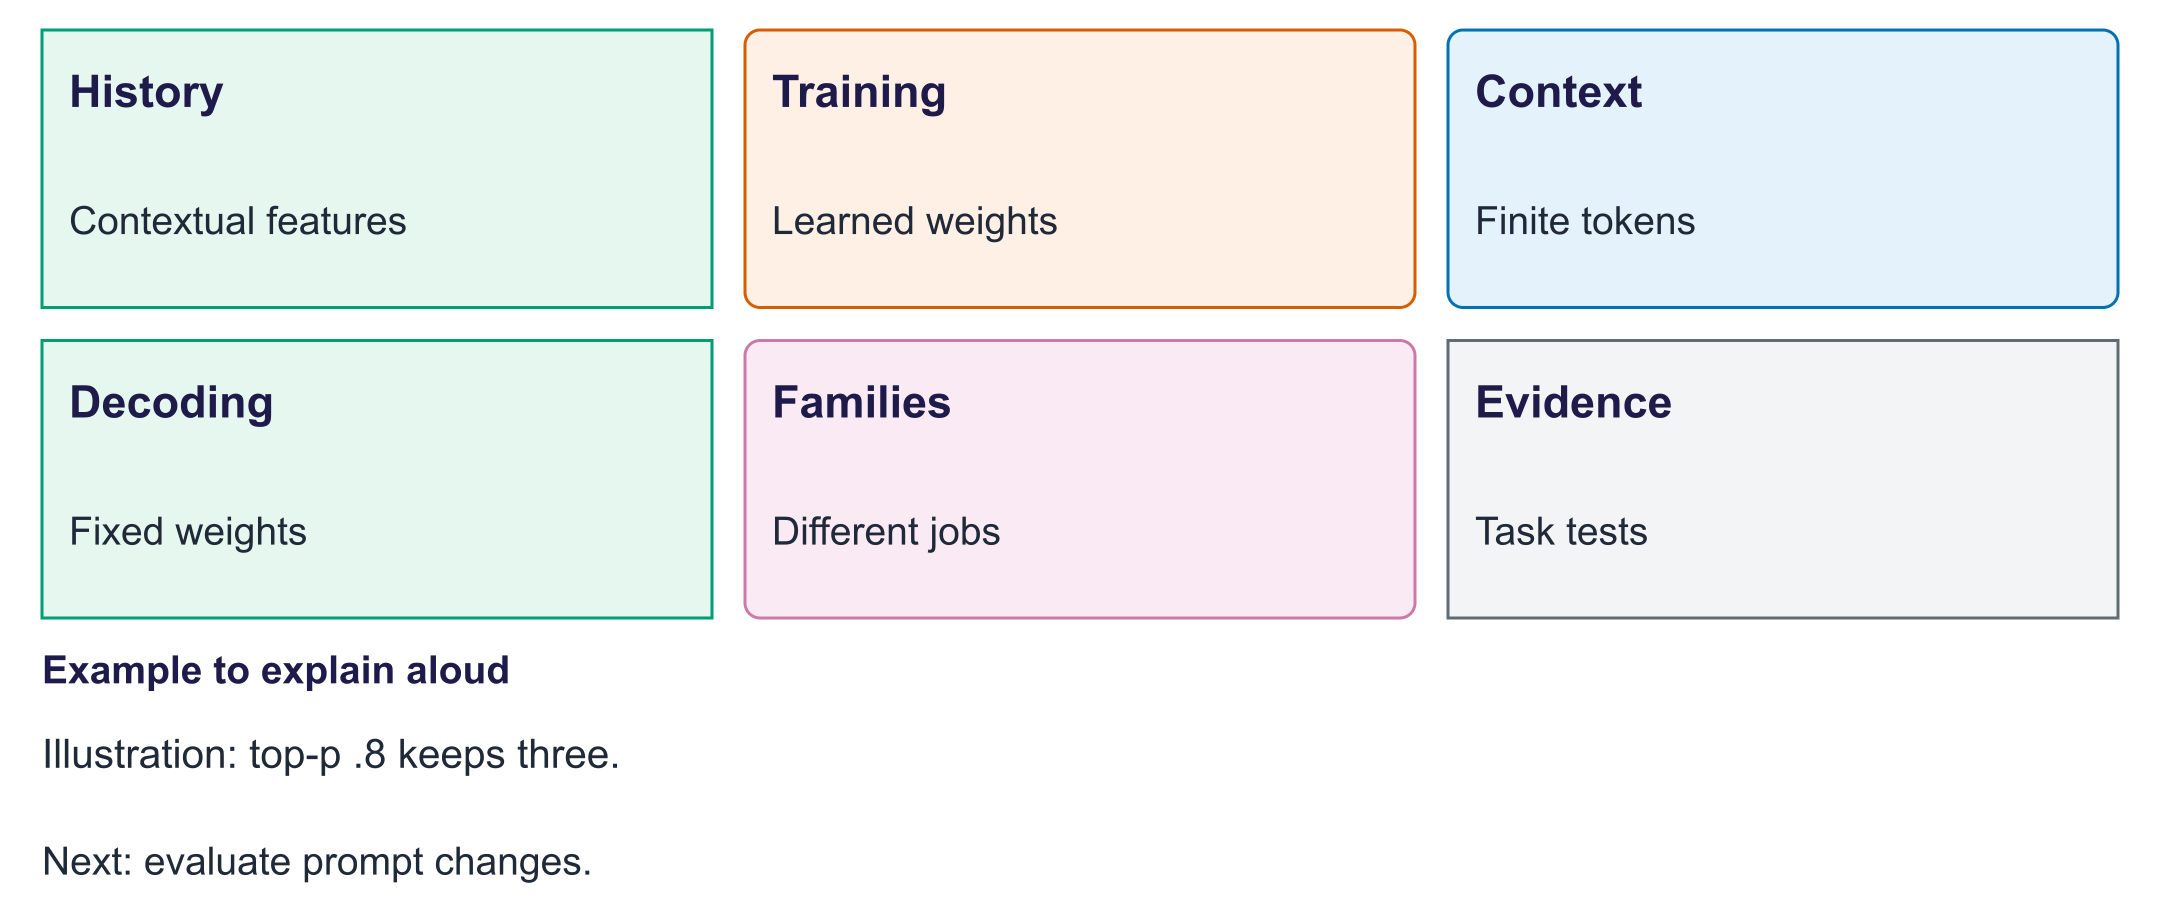

Illustration: top-p .8 keeps three.

**Explain without looking:** Longer thinking proves correctness?